<table style="width:100%; font-size:11pt; border-collapse:collapse">
    <tr>
        <td colspan="2"
            style="border: 1px #44a305 solid;
                   background-color:#F4F9E6;
                   color:#6ba340;
                   text-align:center;
                   font-weight:bold;
                   padding:8px;">
            Universidad de Oriente
        </td>
    </tr>
    <tr>
        <td style="border: 1px #44a305 solid;
                   background-color:#F4F9E6;
                   color:#6ba340;
                   width:50%;
                   text-align:center;
                   padding:6px;">
                            Métodos Numéricos / Oscar Fabricio Guevara Aguilar
        </td>
        <td style="border: 1px #44a305 solid;
                   background-color:#F4F9E6;
                   color:#6ba340;
                   width:50%;
                   text-align:center;
                   padding:6px;">
            Tarea parcial Computo2
        </td>
    </tr>
    <tr>
 

</table>

### 1) Problema 1: Método de Chun

A continuación, se define el método de Chun de la siguiente manera:
$$y_{k}=x_{k}-\frac{f(x_{k})}{f^{\prime}(x_{k})}$$
$$x_{k+1}=y_{k}-\frac{f(x_{k})+2f(y_{k})}{f(x_{k})}\frac{f(y_{k})}{f^{\prime}(x_{k})}$$

a) Programar el método de Chun en Python.
b) Resolver la ecuación utilizando el método de Chun: $(x-1)^{3}-1+e^{x}=0$, utilizando una estimación de $x_{0}=0.1$ y una tolerancia de $10^{-7}$. Obtener la solución aproximada, el error, la cantidad de iteraciones realizadas y el ACOC.

In [1]:
import numpy as np
import math

def f_chun(x):
    return (x - 1)**3 - 1 + np.exp(x)

def df_chun(x):
    return 3*(x - 1)**2 + np.exp(x)

def metodo_chun(f, df, x0, tol, maxiter):
    x = x0
    errores = []

    for i in range(maxiter):
        fx = f(x)
        dfx = df(x)
        if dfx == 0: break

        y = x - fx / dfx
        fy = f(y)

        x_new = y - ((fx + 2*fy) / fx) * (fy / dfx)
        error = abs(x_new - x)
        errores.append(error)

        if error < tol:
            break
        x = x_new

    e_np = np.array(errores)
    if len(e_np) > 2:
        acoc = np.log(e_np[2:] / e_np[1:-1]) / np.log(e_np[1:-1] / e_np[0:-2])
    else:
        acoc = "Iteraciones insuficientes"

    return x_new, i + 1, error, acoc

sol1, iters1, err1, acoc1 = metodo_chun(f_chun, df_chun, 0.1, 1e-7, 50)
print("--- RESULTADOS MÉTODO DE CHUN ---")
print("Solución aproximada: %s" % sol1)
print("Cantidad de iteraciones: %s" % iters1)
print("Error final: %s" % err1)
print("ACOC por iteración: %s" % acoc1)

--- RESULTADOS MÉTODO DE CHUN ---
Solución aproximada: 0.2975706656987736
Cantidad de iteraciones: 3
Error final: 1.3433698597964394e-13
ACOC por iteración: [4.02460381]


### 2) Problema 3: Método MMC2

El método MMC2 está definido de la siguiente manera:
$$y_{k}=x_{k}-\frac{f(x_{k})}{f^{\prime}(x_{k})}$$
$$z_{k}=y_{k}-\frac{f(x_{k})}{f(x_{k})-2f(y_{k})}\frac{f(y_{k})}{f^{\prime}(x_{k})}$$
$$x_{k+1}=z_{k}-\left(2+3\frac{f(y_{k})}{f(x_{k})}-\frac{f(x_{k})}{f(x_{k})-f(y_{k})}\right)\frac{f(z_{k})}{f^{\prime}(x_{k})}$$

a) Programar el método MMC2 en Python.
b) Resolver utilizando el método MMC2 la ecuación: $\sqrt{x^{2}+2x+5}-2\sin(x)+x^{2}-3=0$, utilizando una estimación de $x_{0}=3$ y una tolerancia de $10^{-12}$. Obtener la solución aproximada, el error, la cantidad de iteraciones realizadas y el ACOC.

In [ ]:
def f_mmc2(x):
    return np.sqrt(x**2 + 2*x + 5) - 2*np.sin(x) + x**2 - 3

def df_mmc2(x):
    return (2*x + 2) / (2*np.sqrt(x**2 + 2*x + 5)) - 2*np.cos(x) + 2*x

def metodo_mmc2(f, df, x0, tol, maxiter):
    x = x0
    errores = []

    for i in range(maxiter):
        fx = f(x)
        dfx = df(x)
        if dfx == 0: break

        y = x - fx / dfx
        fy = f(y)

        z = y - (fx / (fx - 2*fy)) * (fy / dfx)
        fz = f(z)

        t_izq = 2 + 3*(fy / fx) - (fx / (fx - fy))
        t_der = fz / dfx

        x_new = z - t_izq * t_der
        error = abs(x_new - x)
        errores.append(error)

        if error < tol:
            break
        x = x_new

    e_np = np.array(errores)
    if len(e_np) > 2:
        acoc = np.log(e_np[2:] / e_np[1:-1]) / np.log(e_np[1:-1] / e_np[0:-2])
    else:
        acoc = "Iteraciones insuficientes"

    return x_new, i + 1, error, acoc

sol3, iters3, err3, acoc3 = metodo_mmc2(f_mmc2, df_mmc2, 3.0, 1e-12, 50)
print("--- RESULTADOS MÉTODO MMC2 ---")
print("Solución aproximada: %s" % sol3)
print("Cantidad de iteraciones: %s" % iters3)
print("Error final: %s" % err3)
print("ACOC por iteración: %s" % acoc3)

--- RESULTADOS MÉTODO MMC2 ---
Solución aproximada: 1.3641174263537554
Cantidad de iteraciones: 4
Error final: 1.5543122344752192e-15
ACOC por iteración: [4.4498866  1.14269707]


### 3) Problema 7: Comparación de Métodos para Sistemas No Lineales

Se considera el sistema no lineal:
$$3x^{2}-y^{2}=0$$
$$3xy^{2}-x^{3}-1=0$$

a) Obtener la matriz jacobiana asociada al sistema no lineal de ecuaciones (Ver imagen adjunta con el procedimiento manual).
b) Resolver el sistema anterior usando los métodos de Newton, Simpson y Trapecios usando la estimación inicial $x^{(0)}=(1,1)^{T}$ y una tolerancia de $10^{-6}$. Obtener por cada método la solución aproximada, el error y la cantidad de iteraciones realizadas.

*(Arrastra y suelta aquí la fotografía de tu cálculo de la Matriz Jacobiana a lápiz. Al soltarla, se generará un código automático que mostrará la imagen al compilar la celda).*

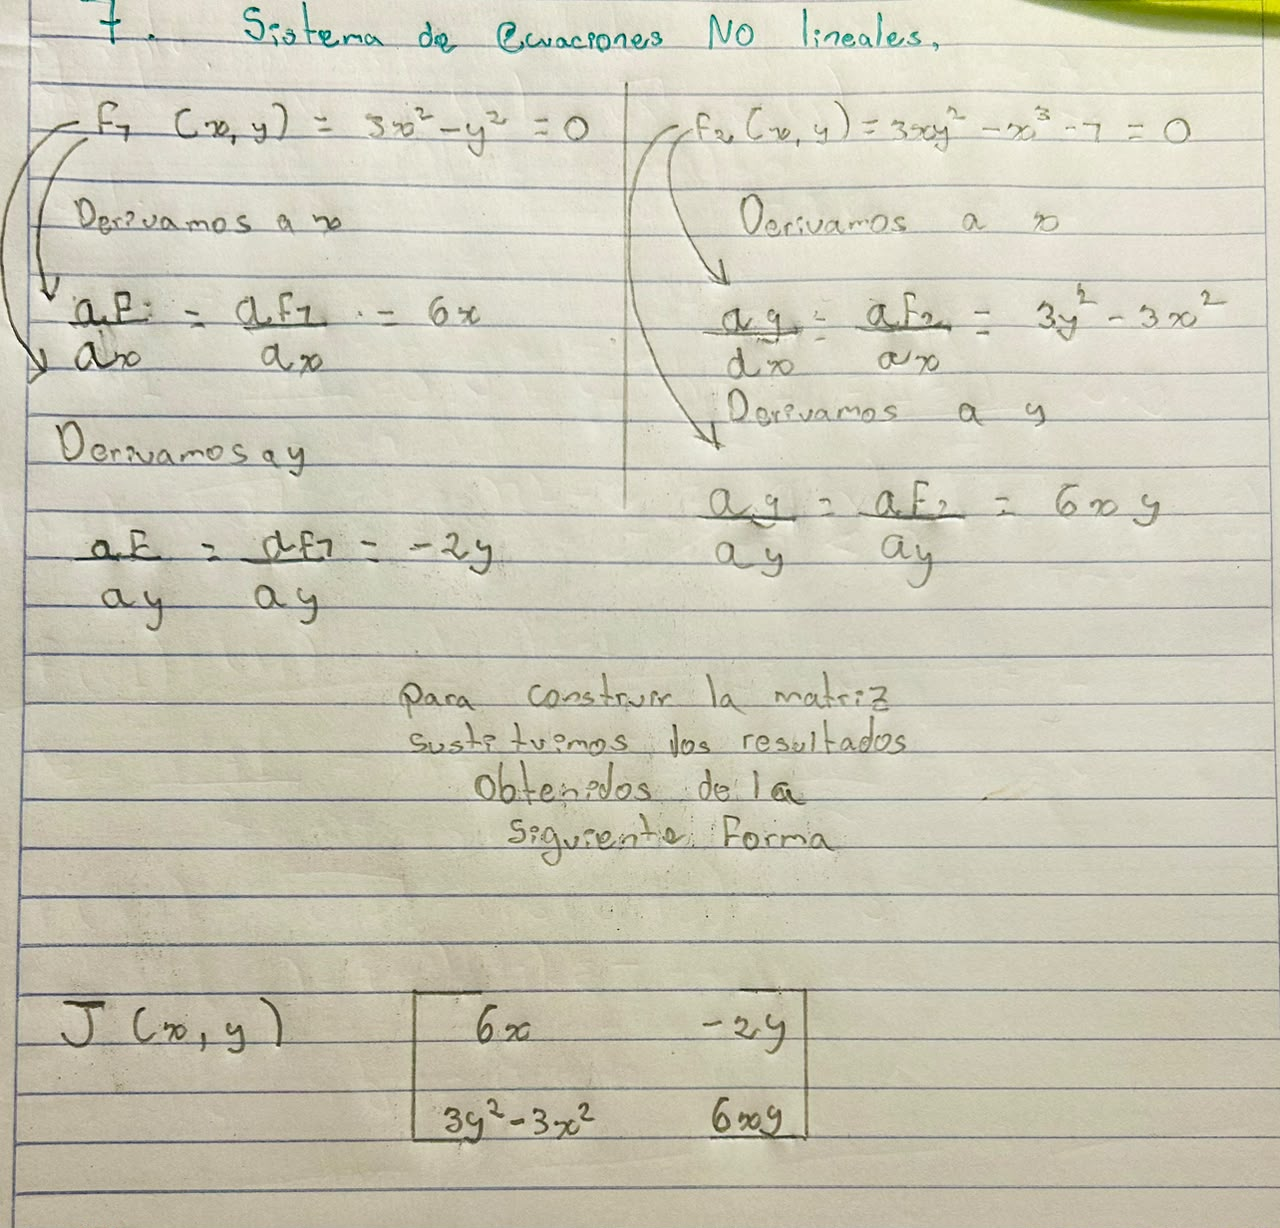

In [3]:
import pandas as pd

def F_sis(v):
    x, y = v[0], v[1]
    return np.array([
        3*x**2 - y**2,
        3*x*y**2 - x**3 - 1
    ])

def JF_sis(v):
    x, y = v[0], v[1]
    return np.array([
        [6*x, -2*y],
        [3*y**2 - 3*x**2, 6*x*y]
    ])

def sys_newton(F, JF, x0, tol, maxiter=50):
    x = np.array(x0, dtype=float)
    for i in range(maxiter):
        delta = np.linalg.solve(JF(x), -F(x))
        x_new = x + delta
        error = np.linalg.norm(delta)
        if error < tol: return x_new, i + 1, error
        x = x_new
    return x, maxiter, error

def sys_trapecios(F, JF, x0, tol, maxiter=50):
    x = np.array(x0, dtype=float)
    for i in range(maxiter):
        y = x - np.linalg.solve(JF(x), F(x))
        delta = np.linalg.solve((JF(x) + JF(y))/2, F(x))
        x_new = x - delta
        error = np.linalg.norm(x_new - x)
        if error < tol: return x_new, i + 1, error
        x = x_new
    return x, maxiter, error

def sys_simpson(F, JF, x0, tol, maxiter=50):
    x = np.array(x0, dtype=float)
    for i in range(maxiter):
        y = x - np.linalg.solve(JF(x), F(x))
        mid = (x + y)/2
        delta = np.linalg.solve((JF(x) + 4*JF(mid) + JF(y))/6, F(x))
        x_new = x - delta
        error = np.linalg.norm(x_new - x)
        if error < tol: return x_new, i + 1, error
        x = x_new
    return x, maxiter, error

x0_sis = [1.0, 1.0]
tol_sis = 1e-6

sol_n, it_n, err_n = sys_newton(F_sis, JF_sis, x0_sis, tol_sis)
sol_t, it_t, err_t = sys_trapecios(F_sis, JF_sis, x0_sis, tol_sis)
sol_s, it_s, err_s = sys_simpson(F_sis, JF_sis, x0_sis, tol_sis)

tabla = pd.DataFrame({
    "Método": ["Newton", "Trapecios", "Simpson"],
    "Solución [x, y]": [sol_n, sol_t, sol_s],
    "Iteraciones": [it_n, it_t, it_s],
    "Error": [err_n, err_t, err_s]
})

print("--- COMPARACIÓN DE MÉTODOS (SISTEMA NO LINEAL) ---")
display(tabla)

--- COMPARACIÓN DE MÉTODOS (SISTEMA NO LINEAL) ---


,Método,"Solución [x, y]",Iteraciones,Error
0,Newton,"[0.5, 0.8660254037844387]",5,1.967492e-09
1,Trapecios,"[0.5, 0.8660254037844386]",4,1.221258e-14
2,Simpson,"[0.5, 0.8660254037844387]",4,2.155663e-15
